In [2]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 481.9 kB/s eta 0:01:41
    -------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, roc_auc_score, recall_score
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from ucimlrepo import fetch_ucirepo

sns.set_theme(style="whitegrid")

In [2]:
dataset = fetch_ucirepo(id=468)

x = dataset.data.features
y = dataset.data.targets

df = pd.concat([x,y],axis=1)

In [5]:
df.shape

(12330, 18)

In [6]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [9]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


In [10]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("Duplicates:")
print(df.duplicated().sum())

print("Target Distribution:")
print(df["Revenue"].value_counts())

Missing Values:
0
Duplicates:
125
Target Distribution:
Revenue
False    10422
True      1908
Name: count, dtype: int64


In [11]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset Shape After Removing Duplicates:", df.shape)

print("Remaining Duplicates:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (12205, 18)
Remaining Duplicates: 0


In [12]:
# Convert target into binary values
df["Revenue"] = df["Revenue"].astype(int)

print(df["Revenue"].value_counts())

Revenue
0    10297
1     1908
Name: count, dtype: int64


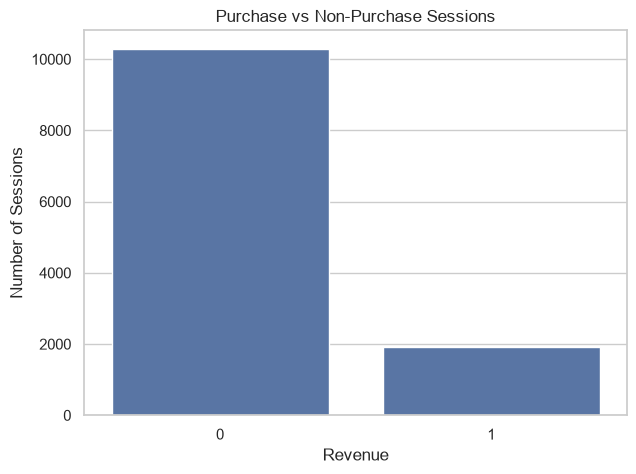

In [ ]:
# target Distripution 
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Revenue")

plt.title("Purchase vs Non-Purchase Sessions")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")

plt.show()

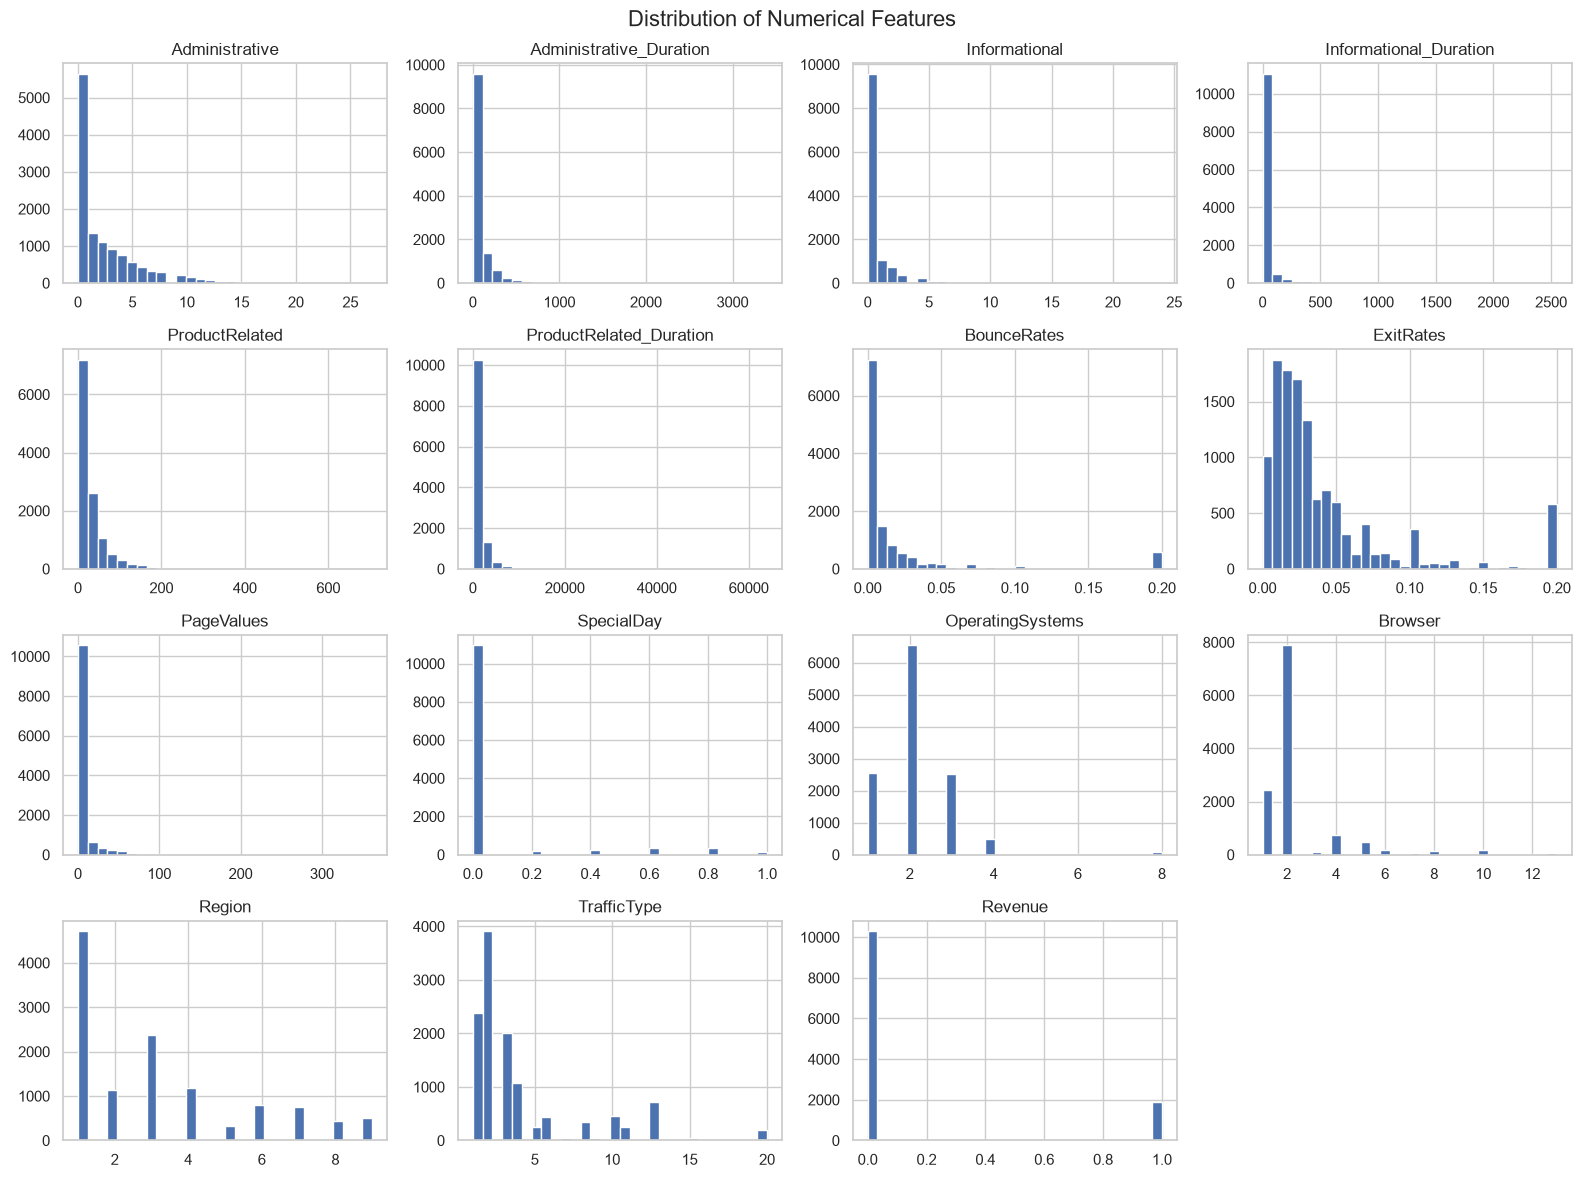

In [14]:
# Numerical features distribution
df.hist(figsize=(16, 12), bins=30)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

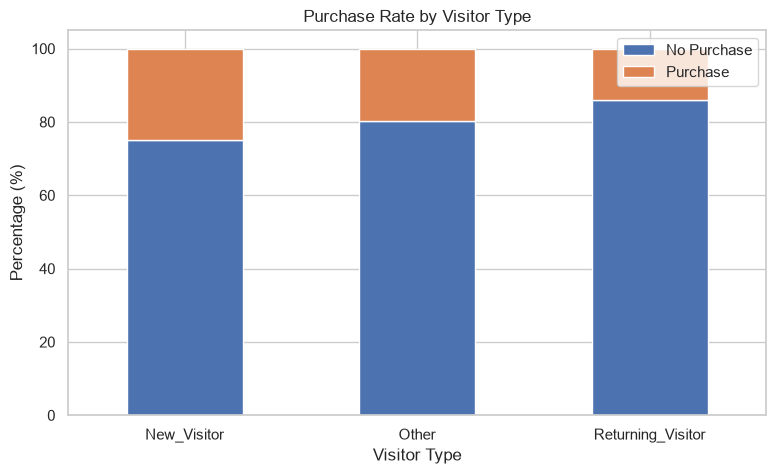

In [16]:
# Purchase Behavior by Visitor Type

visitor_purchase = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

visitor_purchase.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Purchase Rate by Visitor Type")
plt.ylabel("Percentage (%)")
plt.xlabel("Visitor Type")
plt.xticks(rotation=0)
plt.legend(["No Purchase", "Purchase"])
plt.show()

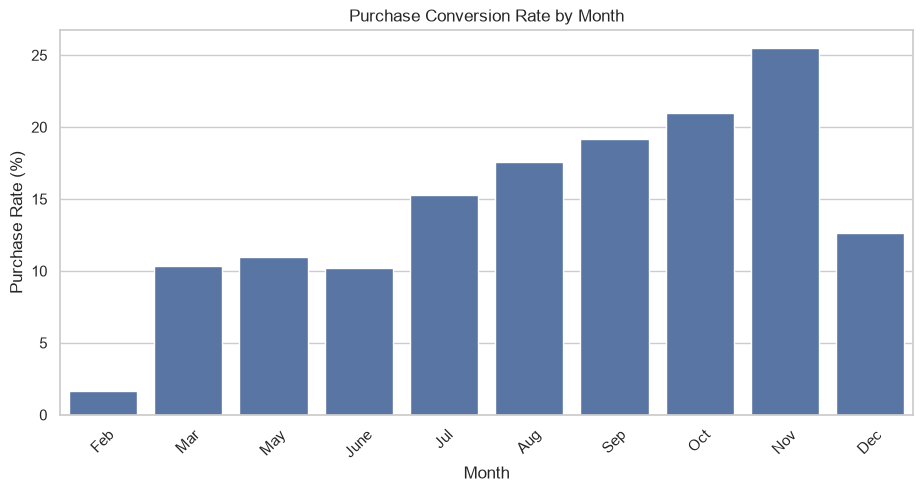

In [ ]:
# Purchase Rate by Month
monthly_purchase = df.groupby("Month")["Revenue"].mean() * 100

month_order = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_purchase = monthly_purchase.reindex(month_order)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=monthly_purchase.index,
    y=monthly_purchase.values
)

plt.title("Purchase Conversion Rate by Month")
plt.ylabel("Purchase Rate (%)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.show()

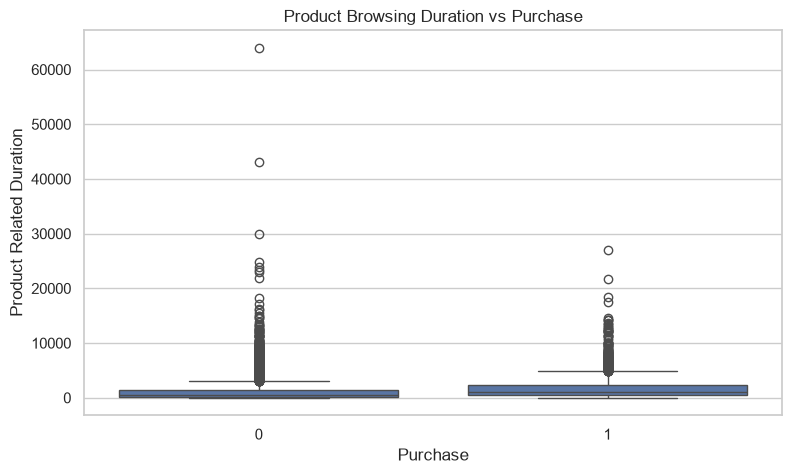

In [18]:
# Product Browsing Behavior
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Revenue",
    y="ProductRelated_Duration"
)

plt.title("Product Browsing Duration vs Purchase")
plt.xlabel("Purchase")
plt.ylabel("Product Related Duration")
plt.show()

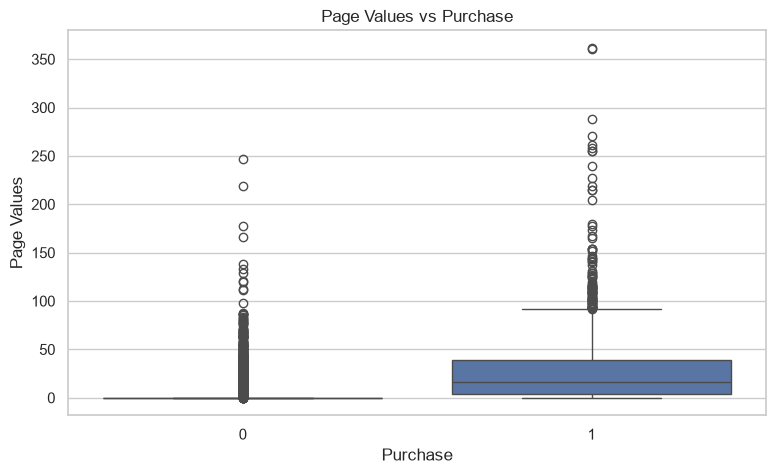

In [ ]:
plt.figure(figsize=(9, 5))  # Page Values Analysis

sns.boxplot(
    data=df,
    x="Revenue",
    y="PageValues"
)

plt.title("Page Values vs Purchase")
plt.xlabel("Purchase")
plt.ylabel("Page Values")
plt.show()

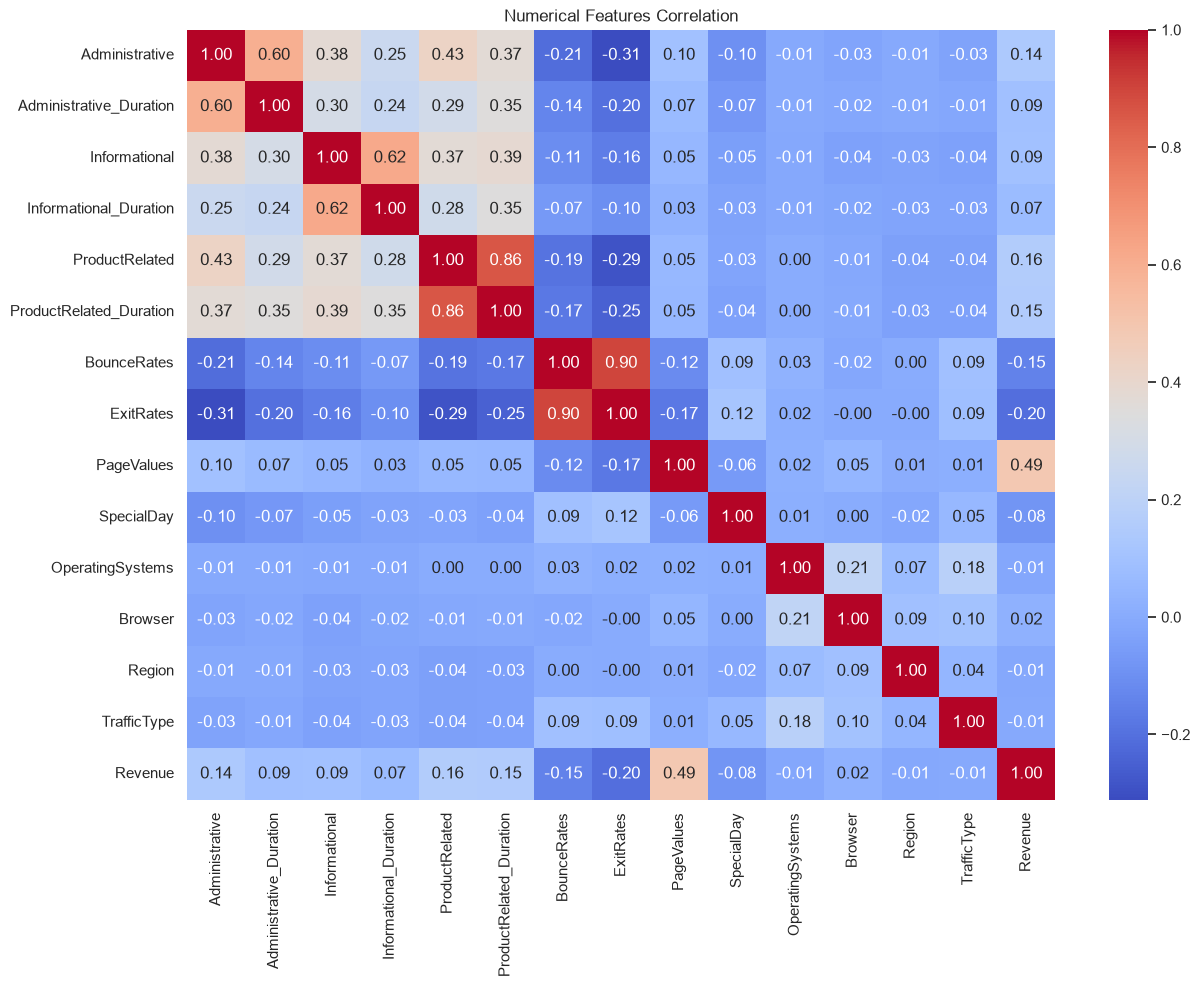

In [20]:
plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Numerical Features Correlation")
plt.show()

In [21]:
features_to_analyze = [
    "Weekend",
    "VisitorType",
    "Browser",
    "TrafficType",
    "Region"
]

for feature in features_to_analyze:

    result = df.groupby(feature)["Revenue"].agg(
        ["count", "mean"]
    )

    result["Purchase_Rate"] = result["mean"] * 100

    print(f"\nPurchase Rate by {feature}")
    display(
        result.sort_values(
            "Purchase_Rate",
            ascending=False
        )
    )


Purchase Rate by Weekend


,count,mean,Purchase_Rate
Weekend,,,
True,2859,0.174537,17.453655
False,9346,0.150760,15.075968



Purchase Rate by VisitorType


,count,mean,Purchase_Rate
VisitorType,,,
New_Visitor,1693,0.249262,24.926167
Other,81,0.197531,19.753086
Returning_Visitor,10431,0.140926,14.092609



Purchase Rate by Browser


,count,mean,Purchase_Rate
Browser,,,
12,10,0.300000,30.000000
13,56,0.285714,28.571429
10,163,0.196319,19.631902
5,465,0.184946,18.494624
4,731,0.177839,17.783858
11,6,0.166667,16.666667
8,135,0.155556,15.555556
2,7883,0.155144,15.514398
1,2427,0.150391,15.039143



Purchase Rate by TrafficType


,count,mean,Purchase_Rate
TrafficType,,,
16,3,0.333333,33.333333
7,40,0.300000,30.000000
8,343,0.276968,27.696793
20,193,0.259067,25.906736
2,3911,0.216569,21.656865
5,260,0.215385,21.538462
10,450,0.200000,20.000000
11,247,0.190283,19.028340
4,1066,0.154784,15.478424



Purchase Rate by Region


,count,mean,Purchase_Rate
Region,,,
9,505,0.170297,17.029703
2,1128,0.166667,16.666667
1,4714,0.163555,16.355537
5,318,0.163522,16.352201
7,758,0.156992,15.699208
4,1171,0.149445,14.944492
3,2379,0.146700,14.670029
6,801,0.139825,13.982522
8,431,0.129930,12.993039


In [22]:
outlier_features = [
    "PageValues",
    "ProductRelated_Duration"
]

for col in outlier_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"\nFeature: {col}")
    print("Outliers:", len(outliers))
    print("Percentage:", round(len(outliers)/len(df)*100, 2), "%")
    print("Skewness:", round(df[col].skew(), 2))


Feature: PageValues
Outliers: 2730
Percentage: 22.37 %
Skewness: 6.35

Feature: ProductRelated_Duration
Outliers: 951
Percentage: 7.79 %
Skewness: 7.25


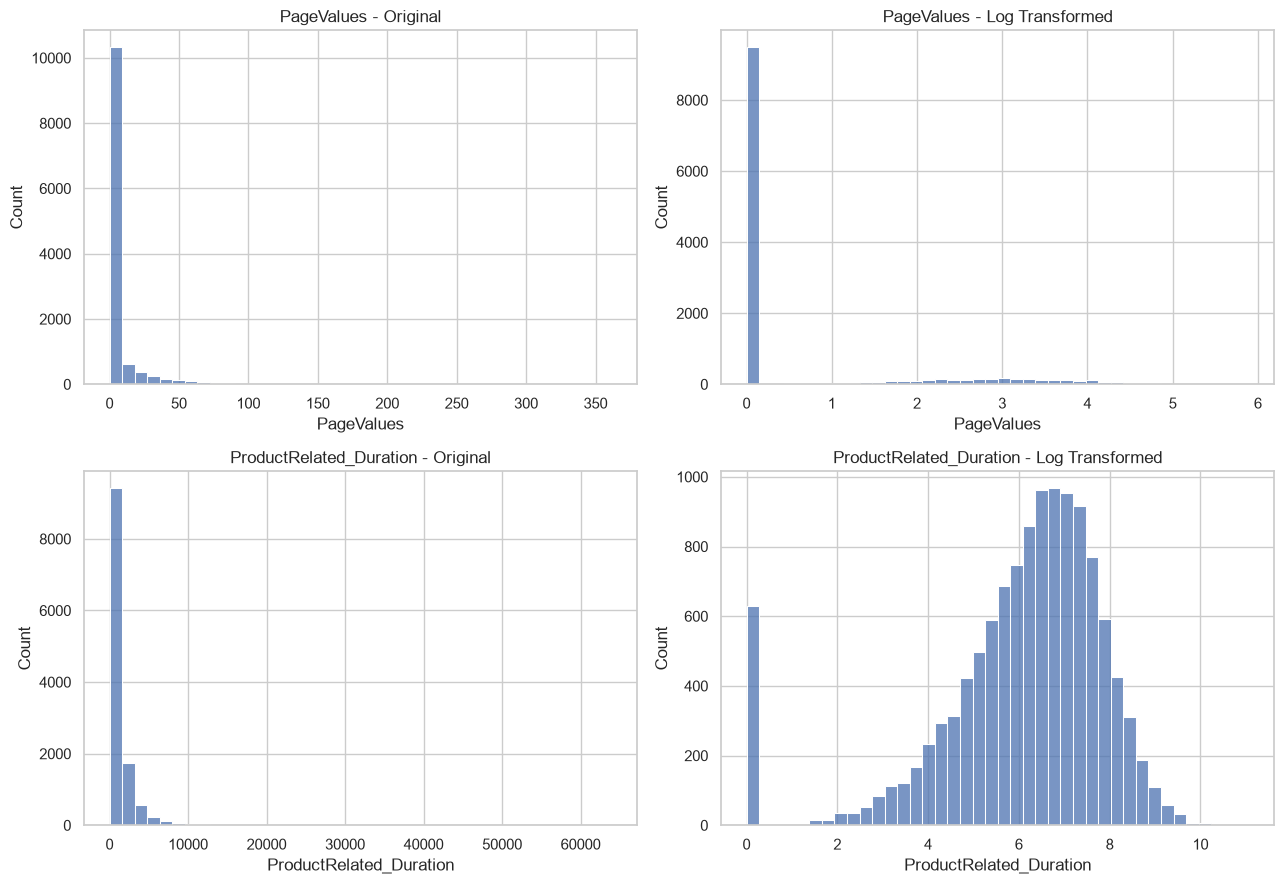

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, col in enumerate(outlier_features):

    sns.histplot(
        df[col],
        bins=40,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"{col} - Original")

    sns.histplot(
        np.log1p(df[col]),
        bins=40,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"{col} - Log Transformed")

plt.tight_layout()
plt.show()

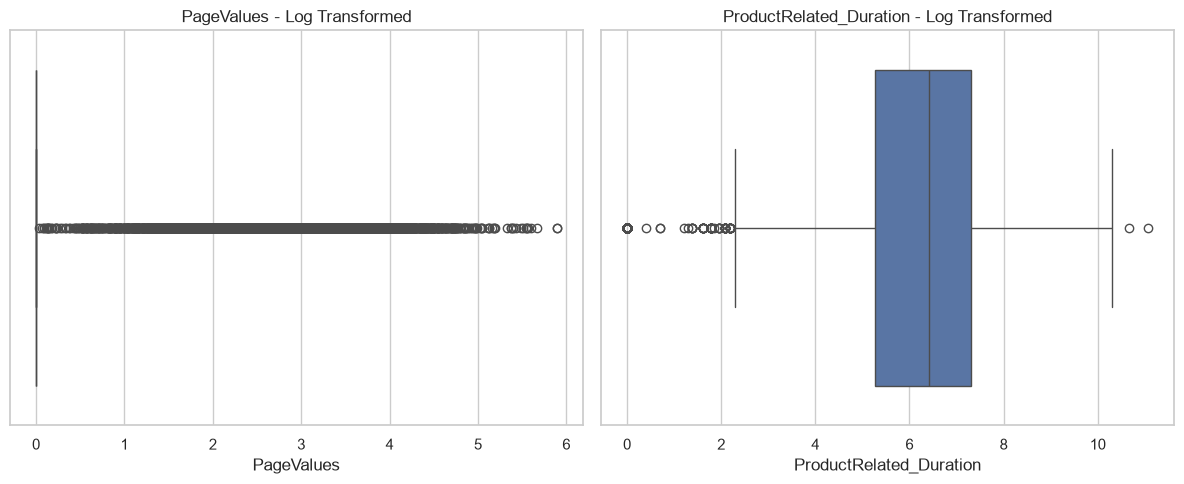

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, col in enumerate(outlier_features):

    sns.boxplot(
        x=np.log1p(df[col]),
        ax=axes[i]
    )

    axes[i].set_title(f"{col} - Log Transformed")

plt.tight_layout()
plt.show()

In [25]:
for col in outlier_features:

    transformed = np.log1p(df[col])

    print(f"\nFeature: {col}")
    print("Original Skewness:", df[col].skew())
    print("Transformed Skewness:", transformed.skew())


Feature: PageValues
Original Skewness: 6.350982660300596
Transformed Skewness: 1.789606719609043

Feature: ProductRelated_Duration
Original Skewness: 7.253161075538186
Transformed Skewness: -1.427148197158478


In [26]:
for col in ["PageValues", "ProductRelated_Duration"]:

    transformed = np.log1p(df[col])

    Q1 = transformed.quantile(0.25)
    Q3 = transformed.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (transformed < lower) |
        (transformed > upper)
    )

    print(f"\nFeature: {col}")
    print("Outliers after Log:", outliers.sum())
    print("Percentage:", round(outliers.mean() * 100, 2), "%")


Feature: PageValues
Outliers after Log: 2730
Percentage: 22.37 %

Feature: ProductRelated_Duration
Outliers after Log: 702
Percentage: 5.75 %


In [27]:
df["HasPageValue"] = (df["PageValues"] > 0).astype(int)

In [28]:
df_model = pd.get_dummies(df, columns=["Month", "VisitorType"], drop_first=True)
df_model["Weekend"] = df_model["Weekend"].astype(int)

In [29]:
X = df_model.drop(columns="Revenue")
y = df_model["Revenue"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (9764, 27)
Test: (2441, 27)


In [35]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   
X_test_scaled = scaler.transform(X_test)

In [41]:
log_plain = LogisticRegression(max_iter=2000)
log_plain.fit(X_train_scaled, y_train)
log_plain_pred = log_plain.predict(X_test_scaled)
log_plain_proba = log_plain.predict_proba(X_test_scaled)[:, 1]

In [42]:
rf_plain = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=3, random_state=42
)
rf_plain.fit(X_train, y_train)
rf_plain_pred = rf_plain.predict(X_test)
rf_plain_proba = rf_plain.predict_proba(X_test)[:, 1]

In [43]:
print("=== Logistic Regression  ===")
print(classification_report(y_test, log_plain_pred))

=== Logistic Regression  ===
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      2059
           1       0.71      0.62      0.66       382

    accuracy                           0.90      2441
   macro avg       0.82      0.79      0.80      2441
weighted avg       0.90      0.90      0.90      2441



In [44]:
print("=== Random Forest  ===")
print(classification_report(y_test, rf_plain_pred))

=== Random Forest  ===
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      2059
           1       0.74      0.62      0.67       382

    accuracy                           0.91      2441
   macro avg       0.84      0.79      0.81      2441
weighted avg       0.90      0.91      0.90      2441



In [46]:
results_plain = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Recall (Buyers)": [recall_score(y_test, log_plain_pred), recall_score(y_test, rf_plain_pred)],
    "F1 (Buyers)": [f1_score(y_test, log_plain_pred), f1_score(y_test, rf_plain_pred)],
    "ROC-AUC": [roc_auc_score(y_test, log_plain_proba), roc_auc_score(y_test, rf_plain_proba)],
}).round(3)

print(results_plain)

                 Model  Recall (Buyers)  F1 (Buyers)  ROC-AUC
0  Logistic Regression            0.618        0.661    0.923
1        Random Forest            0.618        0.673    0.932


In [36]:
log_model = LogisticRegression(max_iter=2000, class_weight="balanced")
log_model.fit(X_train_scaled, y_train)
log_pred = log_model.predict(X_test_scaled)
log_proba = log_model.predict_proba(X_test_scaled)[:, 1]

In [37]:
rf_model = RandomForestClassifier(
    n_estimators=300, class_weight="balanced",
    min_samples_leaf=3, random_state=42
)
rf_model.fit(X_train, y_train)                 
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

In [38]:
print("=== Logistic Regression ===")
print(classification_report(y_test, log_pred))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.96      0.87      0.91      2059
           1       0.54      0.83      0.65       382

    accuracy                           0.86      2441
   macro avg       0.75      0.85      0.78      2441
weighted avg       0.90      0.86      0.87      2441



In [39]:
print("=== Random Forest ===")
print(classification_report(y_test, rf_pred))

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.96      0.89      0.92      2059
           1       0.58      0.79      0.67       382

    accuracy                           0.88      2441
   macro avg       0.77      0.84      0.80      2441
weighted avg       0.90      0.88      0.88      2441



In [40]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "F1 (Buyers)": [f1_score(y_test, log_pred), f1_score(y_test, rf_pred)],
    "ROC-AUC": [roc_auc_score(y_test, log_proba), roc_auc_score(y_test, rf_proba)],
}).round(3)

print(results)

                 Model  F1 (Buyers)  ROC-AUC
0  Logistic Regression        0.654    0.925
1        Random Forest        0.668    0.933


In [49]:
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_proba = dt_model.predict_proba(X_test)[:, 1]


In [50]:
print("=== Decision Tree ===")
print(classification_report(y_test, dt_pred))

=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      2059
           1       0.71      0.64      0.67       382

    accuracy                           0.90      2441
   macro avg       0.82      0.80      0.81      2441
weighted avg       0.90      0.90      0.90      2441



In [51]:
xgb_model = XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    random_state=42, eval_metric="logloss"
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

In [52]:
print("=== XGBoost ===")
print(classification_report(y_test, xgb_pred))

=== XGBoost ===
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      2059
           1       0.70      0.61      0.65       382

    accuracy                           0.90      2441
   macro avg       0.82      0.78      0.80      2441
weighted avg       0.89      0.90      0.90      2441



In [53]:
results_new = pd.DataFrame({
    "Model": ["Decision Tree", "XGBoost"],
    "Recall (Buyers)": [recall_score(y_test, dt_pred), recall_score(y_test, xgb_pred)],
    "F1 (Buyers)": [f1_score(y_test, dt_pred), f1_score(y_test, xgb_pred)],
    "ROC-AUC": [roc_auc_score(y_test, dt_proba), roc_auc_score(y_test, xgb_proba)],
}).round(3)

print(results_new)

           Model  Recall (Buyers)  F1 (Buyers)  ROC-AUC
0  Decision Tree            0.644        0.674    0.925
1        XGBoost            0.610        0.653    0.936


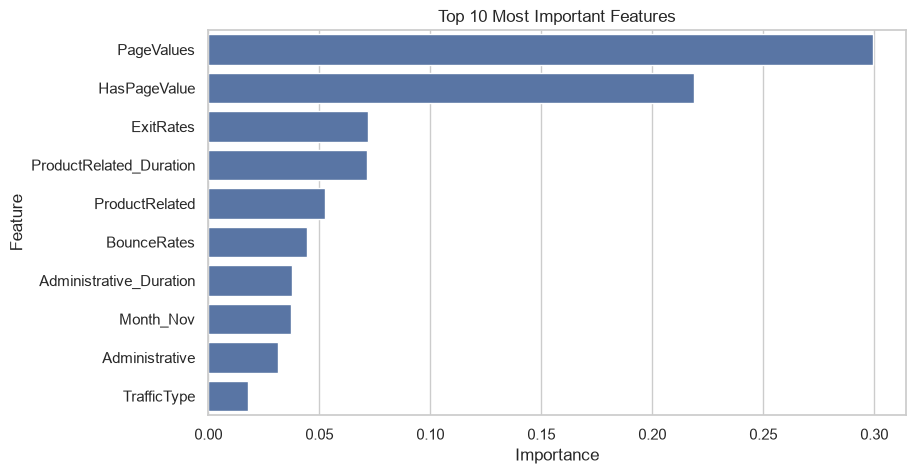

PageValues                 0.299
HasPageValue               0.219
ExitRates                  0.072
ProductRelated_Duration    0.072
ProductRelated             0.052
BounceRates                0.045
Administrative_Duration    0.038
Month_Nov                  0.037
Administrative             0.032
TrafficType                0.018
dtype: float64


In [54]:

importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top10.values, y=top10.index)
plt.title("Top 10 Most Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

print(top10.round(3))

In [55]:
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import precision_score

rf_params = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 8, 12, 16],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": ["sqrt", 0.5],
}

xgb_params = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 4, 6, 8],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
}


searches = {
    "Random Forest": RandomizedSearchCV(
        RandomForestClassifier(random_state=42),
        rf_params, n_iter=15, scoring="f1", cv=3,
        random_state=42, n_jobs=-1),
    "XGBoost": RandomizedSearchCV(
        XGBClassifier(random_state=42, eval_metric="logloss"),
        xgb_params, n_iter=15, scoring="f1", cv=3,
        random_state=42, n_jobs=-1),
}

rows = []
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name} - Best Parameter", search.best_params_)

    best = search.best_estimator_
    pred = best.predict(X_test)
    proba = best.predict_proba(X_test)[:, 1]

    rows.append({
        "Model": name + " (After Tuning)",
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })


for name, m in [("Random Forest (Before Tuning)", rf_plain),
                ("XGBoost (Before Tuning)", xgb_model)]:
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

print(pd.DataFrame(rows).sort_values("Model").round(3).to_string(index=False))

Random Forest - Best Parameter {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8}
XGBoost - Best Parameter {'subsample': 0.85, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.85}
                        Model  Recall  Precision    F1  ROC-AUC
 Random Forest (After Tuning)   0.615      0.732 0.669    0.936
Random Forest (Before Tuning)   0.618      0.740 0.673    0.932
       XGBoost (After Tuning)   0.631      0.730 0.677    0.938
      XGBoost (Before Tuning)   0.610      0.702 0.653    0.936


In [56]:
import joblib

final_model = searches["XGBoost"].best_estimator_

joblib.dump(final_model, "xgb_model.joblib")
joblib.dump(
    {"columns": list(X_train.columns),          
     "defaults": X_train.median().to_dict()},   
    "model_info.joblib"
)
print("Done")

Done


In [3]:
df.to_csv("shoppers_clean.csv", index=False)